# Window KRR Playground: `restaurant`

This notebook treats `restaurant` as its own forecasting problem and uses the
shared window-based kernel ridge regression code in `src/window_krr.py`.

It supports:
- short-term forecasting of `validation \ train` using the `train` split,
- direct test-window forecasting using the `validation` split,
- recursive chunked forecasting from the validation endpoint.

The top parameter cell is meant to be edited freely.

In [1]:
import os
import sys
from pathlib import Path

def _find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "gift_eval").exists():
            return candidate
    raise RuntimeError("Could not locate the KMD_TS repository root from the current working directory.")

REPO_ROOT = _find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

os.environ.setdefault("GIFT_EVAL", str(REPO_ROOT / "GiftEval_data"))
print("Repo root:", REPO_ROOT)
print("GIFT_EVAL:", os.environ["GIFT_EVAL"])

Repo root: /Users/jonghyeonlee/KMD_TS
GIFT_EVAL: /Users/jonghyeonlee/KMD_TS/GiftEval_data


In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt

from gift_eval.data import Dataset
from src.window_krr import (
    KernelConfig,
    WindowKernelRidgeForecaster,
    build_regular_deltas,
    make_windowed_forecasting_dataset,
    relative_l2_error,
)

/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


In [3]:
DATASET_NAME = "restaurant"
TERM = "short"
TO_UNIVARIATE = False

# Pick the series you want to visualize and evaluate.
SERIES_INDEX = 0

# Keep these conservative by default so large datasets stay interactive.
MAX_SERIES = 200
MAX_WINDOWS_PER_SERIES = 20

CONTEXT_LENGTH = 100
SHORT_HORIZON = None         # defaults to dataset.prediction_length
LONG_HORIZON = None          # defaults to dataset.prediction_length
TRAIN_STRIDE = None          # defaults to SHORT_HORIZON
VALIDATION_STRIDE = None     # defaults to LONG_HORIZON

REPRESENTATION = "masked"    # one of: "masked", "interleaved", "plain"
KERNEL_FAMILY = "rbf"        # one of: rbf, matern25, polynomial, laplace, inverse_quadratic, linear
AMPLITUDE = 1.0
LENGTH_SCALE = 5.0
DEGREE = 2
GAMMA = None
COEF0 = 1.0
MASK_MODE = "multiply"       # one of: "none", "multiply", "add"
MASK_SIMILARITY = "jaccard"  # one of: "jaccard", "overlap_fraction", "dot"
MASK_WEIGHT = 1.0
REGULARIZATION = 1e-2

# Test-time controls
TEST_WINDOW_INDEX = 0
ROLLING_TEST_WINDOW_LIMIT = None     # set to an integer to cap rolling evaluation windows
RECURSIVE_TOTAL_HORIZON = None       # defaults to dataset.windows * dataset.prediction_length
RECURSIVE_CHUNK_LENGTH = None        # defaults to LONG_HORIZON

In [4]:
dataset = Dataset(
    name=DATASET_NAME,
    term=TERM,
    to_univariate=TO_UNIVARIATE,
    storage_env_var="GIFT_EVAL",
)

print("dataset_name       :", DATASET_NAME)
print("frequency          :", dataset.freq)
print("prediction_length  :", dataset.prediction_length)
print("test windows/series:", dataset.windows)
print("n_raw_series       :", len(dataset.hf_dataset))
print("target_dim         :", dataset.target_dim)

dataset_name       : restaurant
frequency          : D
prediction_length  : 30
test windows/series: 1
n_raw_series       : 807
target_dim         : 1


In [5]:
def _nth_item(data_it, index: int):
    for i, item in enumerate(data_it):
        if i == index:
            return item
    raise IndexError(f"Index {{index}} is out of range.")


def _series_from_entry(entry) -> np.ndarray:
    return np.asarray(entry["target"], dtype=float).reshape(-1)


def _get_train_entry(series_index: int):
    return _nth_item(dataset.training_dataset, series_index)


def _get_validation_entry(series_index: int):
    return _nth_item(dataset.validation_dataset, series_index)


def _get_test_pair(series_index: int, window_index: int):
    if window_index < 0 or window_index >= dataset.windows:
        raise IndexError(
            f"window_index={{window_index}} is out of range for dataset.windows={{dataset.windows}}."
        )
    flat_index = series_index * dataset.windows + window_index
    test_context = _nth_item(dataset.test_data.input, flat_index)
    test_label = _nth_item(dataset.test_data.label, flat_index)
    return test_context, test_label


def _get_all_test_pairs_for_series(series_index: int, *, limit: int | None = None):
    n_windows = dataset.windows if limit is None else min(int(limit), dataset.windows)
    pairs = []
    for window_index in range(n_windows):
        pairs.append(_get_test_pair(series_index, window_index))
    return pairs


def _validation_minus_train(series_index: int) -> np.ndarray:
    train = _series_from_entry(_get_train_entry(series_index))
    val = _series_from_entry(_get_validation_entry(series_index))
    return val[len(train):]


def _kernel_config() -> KernelConfig:
    return KernelConfig(
        family=KERNEL_FAMILY,
        amplitude=AMPLITUDE,
        length_scale=LENGTH_SCALE,
        degree=DEGREE,
        gamma=GAMMA,
        coef0=COEF0,
        mask_mode=MASK_MODE,
        mask_similarity=MASK_SIMILARITY,
        mask_weight=MASK_WEIGHT,
    )


def _build_window_bank_from_split(
    split_name: str,
    *,
    context_length: int,
    horizon_length: int,
    stride: int | None,
    max_series: int | None,
    max_windows_per_series: int | None,
):
    if split_name not in {"train", "validation"}:
        raise ValueError("split_name must be either 'train' or 'validation'.")
    if context_length <= 0:
        raise ValueError("context_length must be positive.")
    if horizon_length <= 0:
        raise ValueError("horizon_length must be positive.")

    entry_iter = dataset.training_dataset if split_name == "train" else dataset.validation_dataset
    stride = horizon_length if stride is None else int(stride)
    if stride <= 0:
        raise ValueError("stride must be positive.")

    contexts = []
    targets = []
    context_masks = []
    target_masks = []
    context_deltas = []
    target_deltas = []
    used_series = 0
    skipped = []

    for series_index, entry in enumerate(entry_iter):
        if max_series is not None and series_index >= max_series:
            break
        values = _series_from_entry(entry)
        observed_mask = np.isfinite(values)
        deltas = build_regular_deltas(len(values))
        try:
            windowed = make_windowed_forecasting_dataset(
                values,
                context_length=context_length,
                horizon_length=horizon_length,
                observed_mask=observed_mask,
                deltas=deltas,
                stride=stride,
                max_windows=max_windows_per_series,
                include_last=True,
                drop_all_missing_targets=True,
            )
        except ValueError as exc:
            skipped.append((series_index, str(exc)))
            continue

        contexts.append(windowed.contexts)
        targets.append(windowed.targets)
        context_masks.append(windowed.context_masks)
        target_masks.append(windowed.target_masks)
        context_deltas.append(windowed.context_deltas)
        target_deltas.append(windowed.target_deltas)
        used_series += 1

    if not contexts:
        raise ValueError(
            f"No valid windows could be built from split '{{split_name}}'. "
            "Try reducing CONTEXT_LENGTH, LONG_HORIZON/SHORT_HORIZON, or MAX_WINDOWS_PER_SERIES."
        )

    return {
        "contexts": np.vstack(contexts),
        "targets": np.vstack(targets),
        "context_masks": np.vstack(context_masks),
        "target_masks": np.vstack(target_masks),
        "context_deltas": np.vstack(context_deltas),
        "target_deltas": np.vstack(target_deltas),
        "used_series": used_series,
        "n_windows": sum(arr.shape[0] for arr in contexts),
        "skipped": skipped,
    }


def _make_forecaster():
    return WindowKernelRidgeForecaster(
        kernel_config=_kernel_config(),
        representation=REPRESENTATION,
        regularization=REGULARIZATION,
    )


def _plot_forecast(y_true, y_pred, *, title: str, mask=None):
    true_arr = np.asarray(y_true, dtype=float).reshape(-1)
    pred_arr = np.asarray(y_pred, dtype=float).reshape(-1)
    if mask is None:
        obs_mask = np.isfinite(true_arr)
    else:
        obs_mask = np.asarray(mask, dtype=bool).reshape(-1) & np.isfinite(true_arr)

    t = np.arange(1, true_arr.shape[0] + 1)
    plt.figure(figsize=(10, 4))
    plt.plot(t, true_arr, label="true", linewidth=2)
    plt.plot(t, pred_arr, label="predicted", linewidth=2)
    if not obs_mask.all():
        plt.scatter(t[~obs_mask], np.zeros((~obs_mask).sum()), marker="x", label="missing target")
    plt.title(title)
    plt.xlabel("time index within forecast horizon")
    plt.ylabel("value")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

Selected series index: 0
train length         : 406
validation length    : 436
validation\train len : 30


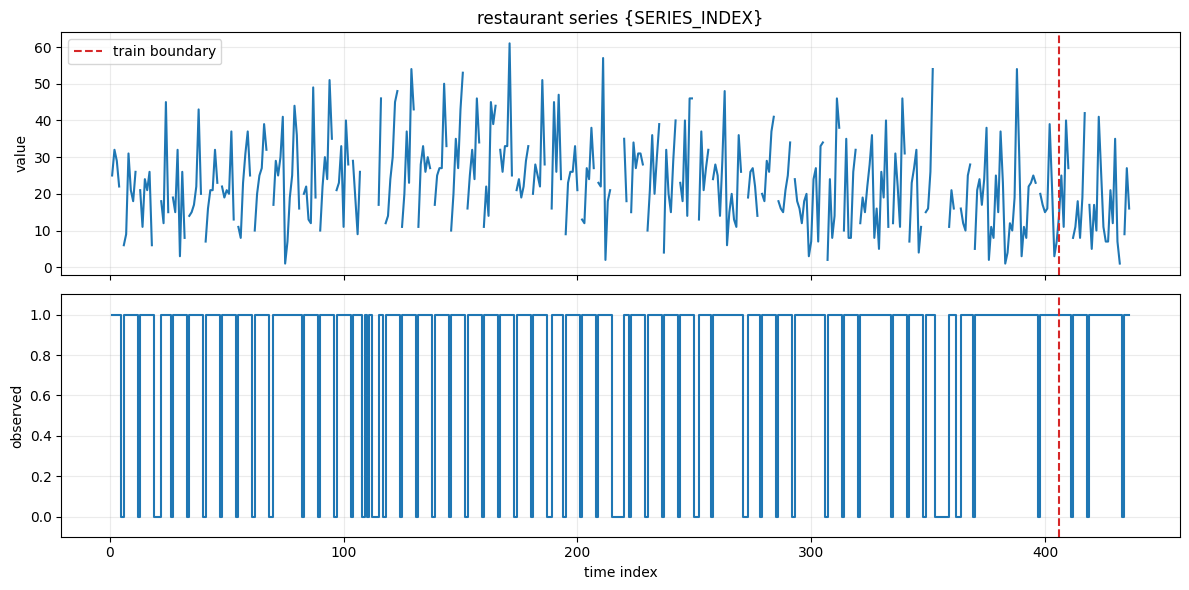

In [6]:
train_entry = _get_train_entry(SERIES_INDEX)
val_entry = _get_validation_entry(SERIES_INDEX)

train_series = _series_from_entry(train_entry)
val_series = _series_from_entry(val_entry)
val_extra = val_series[len(train_series):]
val_mask = np.isfinite(val_series).astype(int)

print("Selected series index:", SERIES_INDEX)
print("train length         :", len(train_series))
print("validation length    :", len(val_series))
print("validation\\train len :", len(val_extra))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(np.arange(1, len(val_series) + 1), val_series, linewidth=1.5)
axes[0].axvline(len(train_series), color="tab:red", linestyle="--", label="train boundary")
axes[0].set_title(f"{DATASET_NAME} series {{SERIES_INDEX}}")
axes[0].set_ylabel("value")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].step(np.arange(1, len(val_mask) + 1), val_mask, where="post")
axes[1].axvline(len(train_series), color="tab:red", linestyle="--")
axes[1].set_ylabel("observed")
axes[1].set_xlabel("time index")
axes[1].set_ylim(-0.1, 1.1)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Short-Term Forecast: `train -> validation \\ train`

Short-term bank windows: 1401
Short-term bank series : 196
Short-term skipped     : 4
Short-term relative L2: 1.3800717297627856


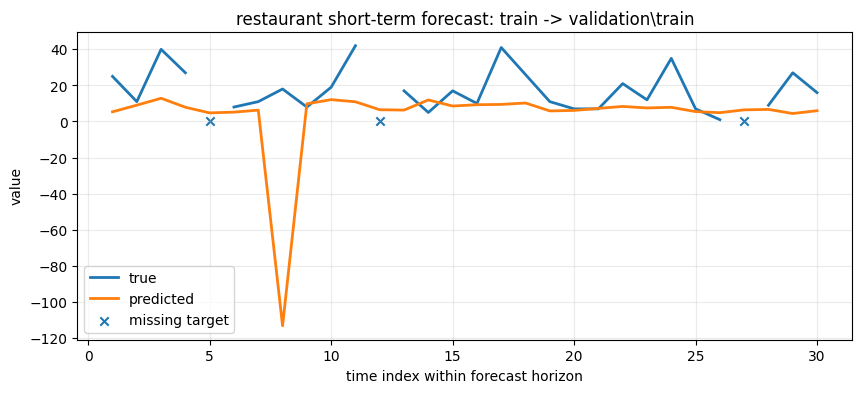

In [7]:
short_horizon = dataset.prediction_length if SHORT_HORIZON is None else int(SHORT_HORIZON)
if short_horizon <= 0:
    raise ValueError("SHORT_HORIZON must be positive.")

val_extra = _validation_minus_train(SERIES_INDEX)
if short_horizon > len(val_extra):
    raise ValueError(
        f"SHORT_HORIZON={{short_horizon}} exceeds len(validation\\train)={{len(val_extra)}}. "
        "Reduce SHORT_HORIZON or use a different development target."
    )

if CONTEXT_LENGTH > len(train_series):
    raise ValueError(
        f"CONTEXT_LENGTH={{CONTEXT_LENGTH}} exceeds training length {{len(train_series)}} "
        f"for series {{SERIES_INDEX}}."
    )

short_bank = _build_window_bank_from_split(
    "train",
    context_length=CONTEXT_LENGTH,
    horizon_length=short_horizon,
    stride=TRAIN_STRIDE,
    max_series=MAX_SERIES,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
)
print("Short-term bank windows:", short_bank["n_windows"])
print("Short-term bank series :", short_bank["used_series"])
print("Short-term skipped     :", len(short_bank["skipped"]))

short_model = _make_forecaster()
short_model.fit(
    short_bank["contexts"],
    short_bank["targets"],
    context_masks=short_bank["context_masks"],
    target_masks=short_bank["target_masks"],
    context_deltas=short_bank["context_deltas"],
)

short_query = train_series[-CONTEXT_LENGTH:]
short_pred = short_model.forecast(
    short_query,
    strategy="direct",
    total_horizon=short_horizon,
    query_masks=np.isfinite(short_query),
    query_deltas=build_regular_deltas(CONTEXT_LENGTH),
).reshape(-1)

short_true = val_extra[:short_horizon]
short_mask = np.isfinite(short_true)
short_rel_l2 = relative_l2_error(short_true, short_pred, mask=short_mask)
print("Short-term relative L2:", short_rel_l2)

_plot_forecast(
    short_true,
    short_pred,
    title=f"{DATASET_NAME} short-term forecast: train -> validation\\train",
    mask=short_mask,
)

## Long-Term Forecast: `validation -> test`

Long-term bank windows: 1599
Long-term bank series : 197
Long-term skipped     : 3
Selected test window index: 0
Long-term relative L2     : 0.852110262270502


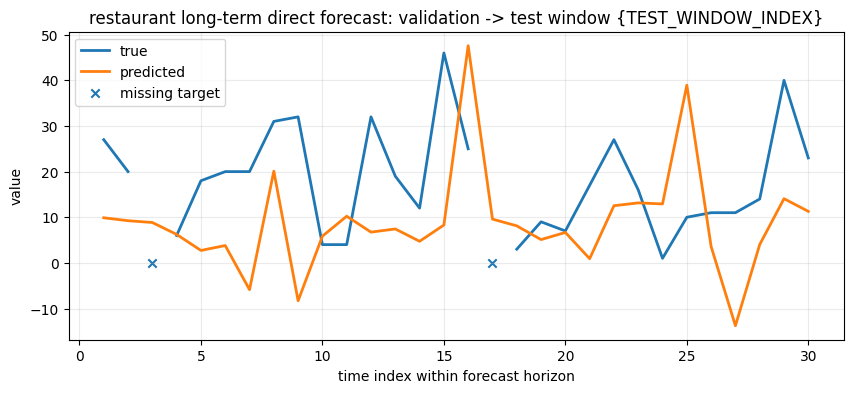

Rolling test windows evaluated: 1
Rolling mean relative L2      : 0.852110262270502
Rolling median relative L2    : 0.852110262270502


In [8]:
long_horizon = dataset.prediction_length if LONG_HORIZON is None else int(LONG_HORIZON)
if long_horizon <= 0:
    raise ValueError("LONG_HORIZON must be positive.")
if CONTEXT_LENGTH > len(val_series):
    raise ValueError(
        f"CONTEXT_LENGTH={{CONTEXT_LENGTH}} exceeds validation length {{len(val_series)}} "
        f"for series {{SERIES_INDEX}}."
    )

validation_bank = _build_window_bank_from_split(
    "validation",
    context_length=CONTEXT_LENGTH,
    horizon_length=long_horizon,
    stride=VALIDATION_STRIDE,
    max_series=MAX_SERIES,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
)
print("Long-term bank windows:", validation_bank["n_windows"])
print("Long-term bank series :", validation_bank["used_series"])
print("Long-term skipped     :", len(validation_bank["skipped"]))

long_model = _make_forecaster()
long_model.fit(
    validation_bank["contexts"],
    validation_bank["targets"],
    context_masks=validation_bank["context_masks"],
    target_masks=validation_bank["target_masks"],
    context_deltas=validation_bank["context_deltas"],
)

test_context_entry, test_label_entry = _get_test_pair(SERIES_INDEX, TEST_WINDOW_INDEX)
test_context = _series_from_entry(test_context_entry)
test_label = _series_from_entry(test_label_entry)
if CONTEXT_LENGTH > len(test_context):
    raise ValueError(
        f"CONTEXT_LENGTH={{CONTEXT_LENGTH}} exceeds the selected test context length {{len(test_context)}}."
    )
if long_horizon > len(test_label):
    raise ValueError(
        f"LONG_HORIZON={{long_horizon}} exceeds the selected test label length {{len(test_label)}}. "
        "For direct test-window prediction, LONG_HORIZON should be at most prediction_length."
    )

long_query = test_context[-CONTEXT_LENGTH:]
long_pred = long_model.forecast(
    long_query,
    strategy="direct",
    total_horizon=long_horizon,
    query_masks=np.isfinite(long_query),
    query_deltas=build_regular_deltas(CONTEXT_LENGTH),
).reshape(-1)

long_true = test_label[:long_horizon]
long_mask = np.isfinite(long_true)
long_rel_l2 = relative_l2_error(long_true, long_pred, mask=long_mask)
print("Selected test window index:", TEST_WINDOW_INDEX)
print("Long-term relative L2     :", long_rel_l2)

_plot_forecast(
    long_true,
    long_pred,
    title=f"{DATASET_NAME} long-term direct forecast: validation -> test window {{TEST_WINDOW_INDEX}}",
    mask=long_mask,
)

all_pairs = _get_all_test_pairs_for_series(SERIES_INDEX, limit=ROLLING_TEST_WINDOW_LIMIT)
rolling_errors = []
for pair_index, (ctx_entry, lbl_entry) in enumerate(all_pairs):
    ctx = _series_from_entry(ctx_entry)
    lbl = _series_from_entry(lbl_entry)
    if CONTEXT_LENGTH > len(ctx) or long_horizon > len(lbl):
        continue
    pred = long_model.forecast(
        ctx[-CONTEXT_LENGTH:],
        strategy="direct",
        total_horizon=long_horizon,
        query_masks=np.isfinite(ctx[-CONTEXT_LENGTH:]),
        query_deltas=build_regular_deltas(CONTEXT_LENGTH),
    ).reshape(-1)
    truth = lbl[:long_horizon]
    rolling_errors.append(relative_l2_error(truth, pred, mask=np.isfinite(truth)))

if rolling_errors:
    print("Rolling test windows evaluated:", len(rolling_errors))
    print("Rolling mean relative L2      :", float(np.mean(rolling_errors)))
    print("Rolling median relative L2    :", float(np.median(rolling_errors)))
else:
    print("No rolling test windows could be evaluated with the current CONTEXT_LENGTH/LONG_HORIZON.")

## Recursive Chunked Forecast from the Validation Endpoint

Recursive total horizon: 30
Recursive relative L2  : 0.852110262270502


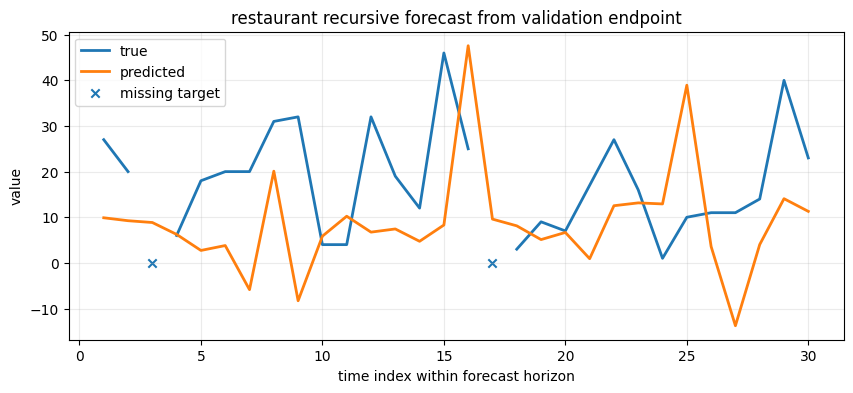

In [9]:
recursive_chunk_length = long_horizon if RECURSIVE_CHUNK_LENGTH is None else int(RECURSIVE_CHUNK_LENGTH)
if recursive_chunk_length <= 0:
    raise ValueError("RECURSIVE_CHUNK_LENGTH must be positive.")
if recursive_chunk_length > long_horizon:
    raise ValueError(
        f"RECURSIVE_CHUNK_LENGTH={{recursive_chunk_length}} exceeds LONG_HORIZON={{long_horizon}}."
    )

test_pairs = _get_all_test_pairs_for_series(SERIES_INDEX)
recursive_truth_blocks = [_series_from_entry(label_entry) for _, label_entry in test_pairs]
recursive_truth = np.concatenate(recursive_truth_blocks)
recursive_mask = np.isfinite(recursive_truth)

recursive_total_horizon = len(recursive_truth) if RECURSIVE_TOTAL_HORIZON is None else int(RECURSIVE_TOTAL_HORIZON)
if recursive_total_horizon <= 0:
    raise ValueError("RECURSIVE_TOTAL_HORIZON must be positive.")
recursive_total_horizon = min(recursive_total_horizon, len(recursive_truth))

recursive_query = val_series[-CONTEXT_LENGTH:]
recursive_pred = long_model.forecast(
    recursive_query,
    strategy="chunked",
    total_horizon=recursive_total_horizon,
    chunk_length=recursive_chunk_length,
    query_masks=np.isfinite(recursive_query),
    query_deltas=build_regular_deltas(CONTEXT_LENGTH),
    future_deltas=np.ones((1, recursive_total_horizon), dtype=float),
).reshape(-1)

recursive_true = recursive_truth[:recursive_total_horizon]
recursive_true_mask = recursive_mask[:recursive_total_horizon]
recursive_rel_l2 = relative_l2_error(recursive_true, recursive_pred, mask=recursive_true_mask)
print("Recursive total horizon:", recursive_total_horizon)
print("Recursive relative L2  :", recursive_rel_l2)

_plot_forecast(
    recursive_true,
    recursive_pred,
    title=f"{DATASET_NAME} recursive forecast from validation endpoint",
    mask=recursive_true_mask,
)